# 04 · Outliers: anomaly detector

**DMDW topics:** statistical outlier detection - z-score (relative to each user's own history) and IQR / box-plot fences.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

from cfiq.config import load_config
from cfiq.db import get_engine, read_sql

cfg = load_config()
engine = get_engine()
REPORTS = cfg["paths"]["reports"]
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
from cfiq.mining import outliers as O

In [2]:
O.run_outliers(cfg, engine)
ranked = pd.read_csv(REPORTS / 'outliers' / 'ranked_anomalies.csv')
ranked[ranked.anomaly_type == 'rating_jump'].head(10)

,anomaly_type,rank,handle,contest_id,contest_name,value,score,detail
0,rating_jump,1,IzhitskiyTimofey,2238,Codeforces Round 1106 (Div. 2),515,4.678,1219 -> 1734 (contest #107 for the user)
1,rating_jump,2,Tlatoani,1774,"Polynomial Round 2022 (Div. 1 + Div. 2, Rated,...",-382,-4.674,2646 -> 2264 (contest #78 for the user)
2,rating_jump,3,QwertyPi,2271,"DeepInfra Round 1 (Codeforces Round 1126, Div....",378,4.408,2503 -> 2881 (contest #183 for the user)
3,rating_jump,4,ksun48,1810,"CodeTON Round 4 (Div. 1 + Div. 2, Rated, Prizes!)",-412,-4.360,3413 -> 3001 (contest #247 for the user)
4,rating_jump,5,AlRntn,2146,Codeforces Round 1052 (Div. 2),275,4.191,2076 -> 2351 (contest #65 for the user)
5,rating_jump,6,Arterm,1055,Mail.Ru Cup 2018 Round 2,-319,-4.170,2656 -> 2337 (contest #161 for the user)
6,rating_jump,7,Wawi,2222,Spectral::Cup 2026 Round 1 (Codeforces Round 1...,-272,-4.154,2189 -> 1917 (contest #90 for the user)
7,rating_jump,8,ApraCadabra,1805,Codeforces Round 862 (Div. 2),-236,-3.934,2028 -> 1792 (contest #71 for the user)
8,rating_jump,9,tourist,947,"Codeforces Round 470 (rated, Div. 1, based on ...",-290,-3.749,3496 -> 3206 (contest #135 for the user)
9,rating_jump,10,shriganesh83,1525,Educational Codeforces Round 109 (Rated for Di...,225,3.663,925 -> 1150 (contest #50 for the user)


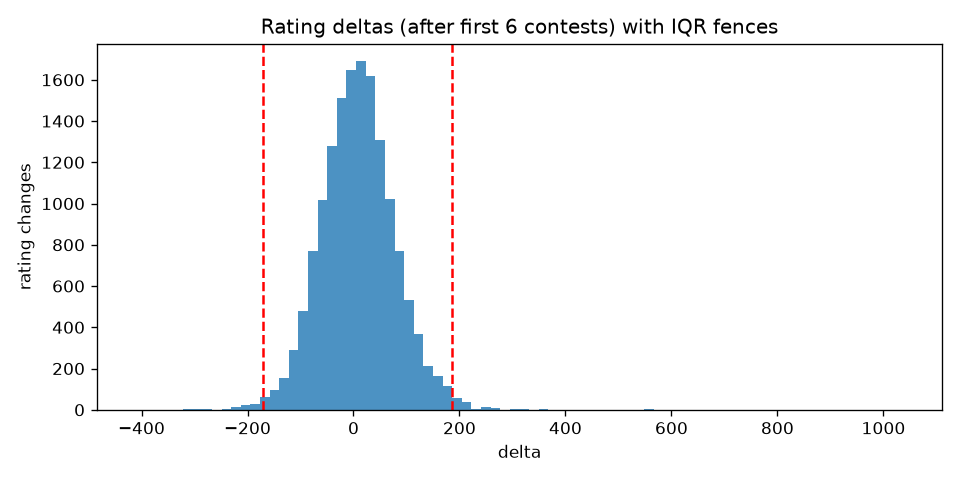

In [3]:
Image(REPORTS / 'outliers' / 'rating_delta_hist.png')

In [4]:
ranked[ranked.anomaly_type == 'submission_burst'].head(10)

,anomaly_type,rank,handle,contest_id,contest_name,value,score,detail
50,submission_burst,1,tourist,1639,Pinely Treasure Hunt Contest,49,59.630,"49 submissions in one 60s window, 520 in the c..."
51,submission_burst,2,p0tato,1639,Pinely Treasure Hunt Contest,47,57.136,"47 submissions in one 60s window, 762 in the c..."
52,submission_burst,3,KostasKostil,1639,Pinely Treasure Hunt Contest,41,49.652,"41 submissions in one 60s window, 297 in the c..."
53,submission_burst,4,baluteshih,1639,Pinely Treasure Hunt Contest,29,34.685,"29 submissions in one 60s window, 404 in the c..."
54,submission_burst,5,Golovanov399,1639,Pinely Treasure Hunt Contest,25,29.696,"25 submissions in one 60s window, 104 in the c..."
55,submission_burst,6,Holpens,1639,Pinely Treasure Hunt Contest,19,22.213,"19 submissions in one 60s window, 275 in the c..."
56,submission_burst,7,maxplus,642,VK Cup 2016 - Wild Card Round 2,15,17.224,"15 submissions in one 60s window, 759 in the c..."
57,submission_burst,8,Golovanov399,921,AIM Tech Mini Marathon 1,14,15.977,"14 submissions in one 60s window, 56 in the co..."
58,submission_burst,9,maxplus,537,VK Cup 2015 - Wild Card Round 2,12,13.482,"12 submissions in one 60s window, 2280 in the ..."
59,submission_burst,10,amirhoseinfar1385,1639,Pinely Treasure Hunt Contest,12,13.482,"12 submissions in one 60s window, 23 in the co..."


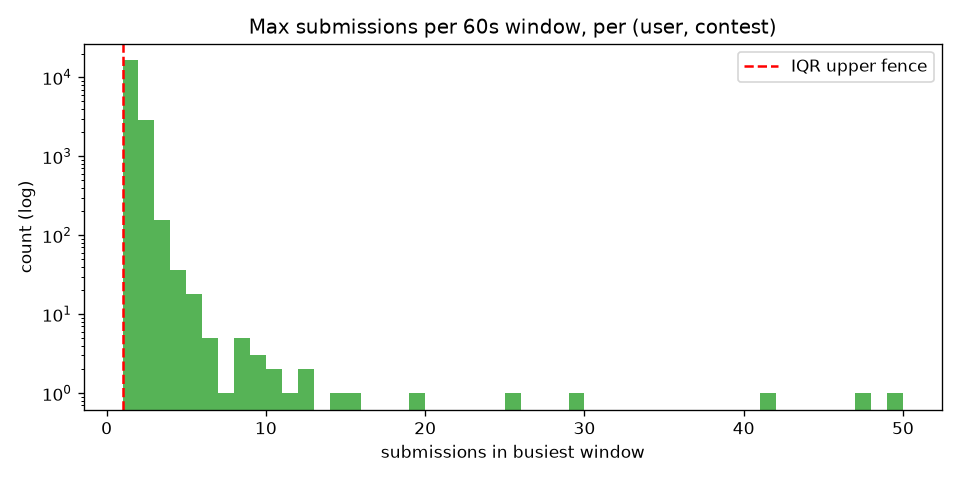

In [5]:
Image(REPORTS / 'outliers' / 'submission_burst_hist.png')